# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba_brakow,odsetek_brakow [%]
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


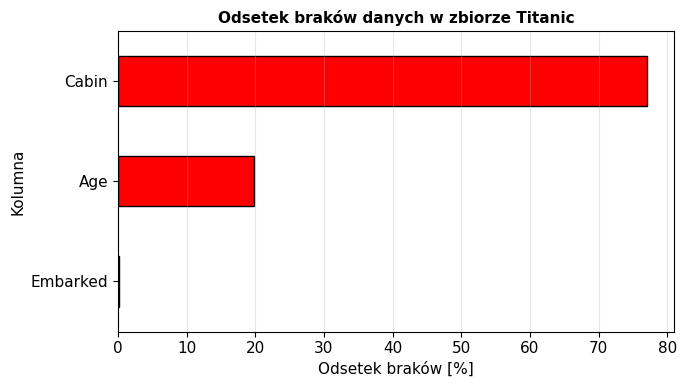

In [3]:
# 1)

braki_liczba = titanic.isna().sum()
braki_procent = (titanic.isna().mean() * 100).round(2)

podsumowanie_brakow = pd.DataFrame({
    "liczba_brakow": braki_liczba,
    "odsetek_brakow [%]": braki_procent
})

braki_do_pokazania = podsumowanie_brakow[podsumowanie_brakow["liczba_brakow"] > 0].sort_values(by="liczba_brakow", ascending=False)
display(braki_do_pokazania)

# 2)

braki_do_pokazania["odsetek_brakow [%]"].sort_values(ascending=True).plot.barh(color="red",edgecolor="black")

plt.title("Odsetek braków danych w zbiorze Titanic", fontsize=11, fontweight="bold")
plt.xlabel("Odsetek braków (%)")
plt.ylabel("Kolumna")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

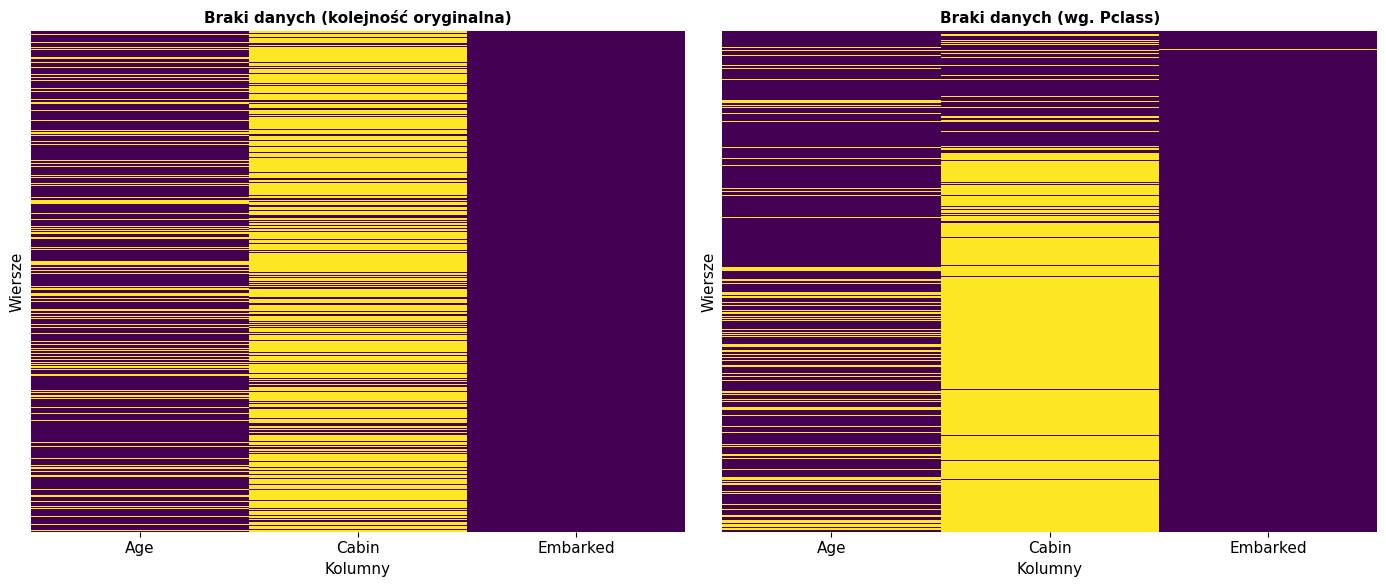

In [5]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1)
sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Braki danych (kolejność oryginalna)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Kolumny")
axes[0].set_ylabel("Wiersze")

# 2)
titanic_posortowany = titanic.sort_values(by="Pclass")
sns.heatmap(titanic_posortowany[kolumny].isna(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Braki danych (wg. Pclass)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Kolumny")
axes[1].set_ylabel("Wiersze")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Na drugim wykresie widać, że braki w kolumnie Cabin nie są losowe tylko zależą od klasy (Pclass). W 1 klasie większość pasażerów ma wpisaną kabinę, natomiast w 2 i w 3 jest mnóstwo braków danych. Na pierwszym wykresie było to widać, jako przypadkowy szum.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku wg klasy:
Pclass
1    13.89
2     5.98
3    27.70
Name: Age, dtype: float64
Odsetek braków wieku wg płci:
Sex
female    16.88
male      21.49
Name: Age, dtype: float64
Odsetek ocalałych:
Znany wiek    40.62
Brak wieku    29.38
Name: Survived, dtype: float64


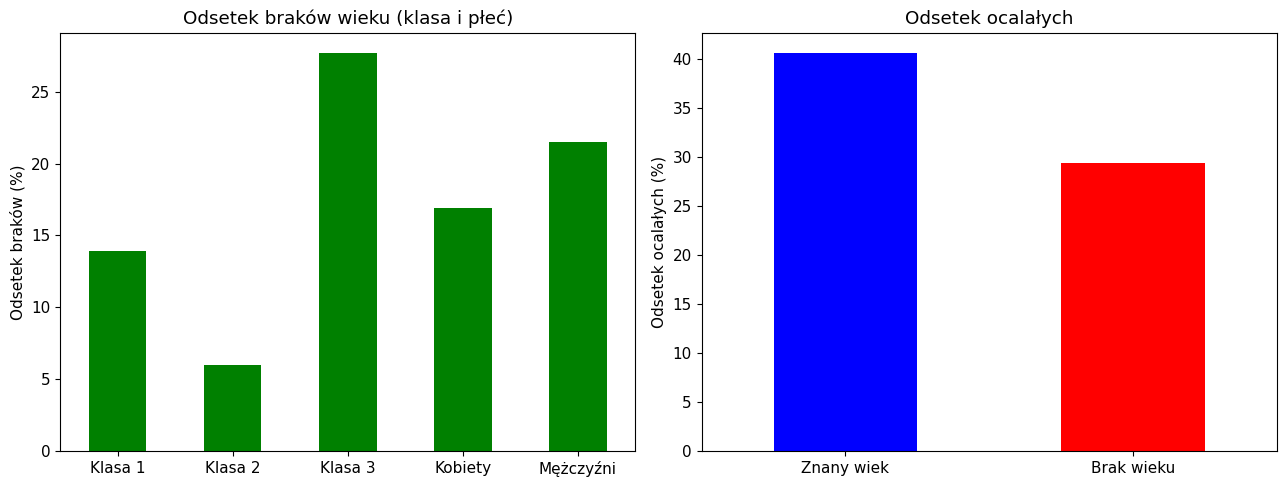

In [11]:
# 1)
brak_wieku = titanic["Age"].isna()

# 2)
odsetek_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
odsetek_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print("Odsetek braków wieku wg klasy:")
print(odsetek_klasa.round(2))
print("Odsetek braków wieku wg płci:")
print(odsetek_plec.round(2))

# 3)
odsetek_ocalalych = titanic.groupby(brak_wieku)["Survived"].mean() * 100
odsetek_ocalalych.index = ["Znany wiek", "Brak wieku"]

print("Odsetek ocalałych:")
print(odsetek_ocalalych.round(2))

# 4)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

braki_razem = pd.concat([odsetek_klasa, odsetek_plec])

braki_razem.plot.bar(ax=axes[0], color="green", rot=0)
axes[0].set_title("Odsetek braków wieku (klasa i płeć)")
axes[0].set_ylabel("Odsetek braków (%)")
axes[0].set_xticklabels(["Klasa 1", "Klasa 2", "Klasa 3", "Kobiety", "Mężczyźni"])

odsetek_ocalalych.plot.bar(ax=axes[1], color=["blue", "red"], rot=0)
axes[1].set_title("Odsetek ocalałych")
axes[1].set_ylabel("Odsetek ocalałych (%)")
axes[1].set_xticklabels(["Znany wiek", "Brak wieku"])

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Nie jest to MCAR, ponieważ braki nie powstały losowo. W przypadku usunięcia wierszy bez wieku, odsetek ocalałych zostałby sztucznie zawyżony.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [12]:
warianty = {
    "bez zmian": titanic,
    'dropna(Embarked)': titanic.dropna(subset=["Embarked"]),
    'dropna(Age)': titanic.dropna(subset=["Age"]),
    'dropna()': titanic.dropna()
}

wyniki = []
for nazwa, df in warianty.items():
    wyniki.append({
        "wariant": nazwa,
        "liczba wierszy": len(df),
        "odsetek ocalałych (%)": round(df["Survived"].mean() * 100, 2),
        "odsetek 1. klasy (%)": round((df["Pclass"] == 1).mean() * 100, 2)
    })

tabela = pd.DataFrame(wyniki).set_index("wariant")
display(tabela)

,liczba wierszy,odsetek ocalałych (%),odsetek 1. klasy (%)
wariant,,,
bez zmian,891,38.38,24.24
dropna(Embarked),889,38.25,24.07
dropna(Age),714,40.62,26.05
dropna(),183,67.21,86.34


*Twoja odpowiedź:* Najbardziej zniekształca dropna(), ponieważ pozbywa się wszystkich wierszy, które zawierają jakikolwiek NaN. W efekcie drastycznie zmienia strukturę zbioru.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

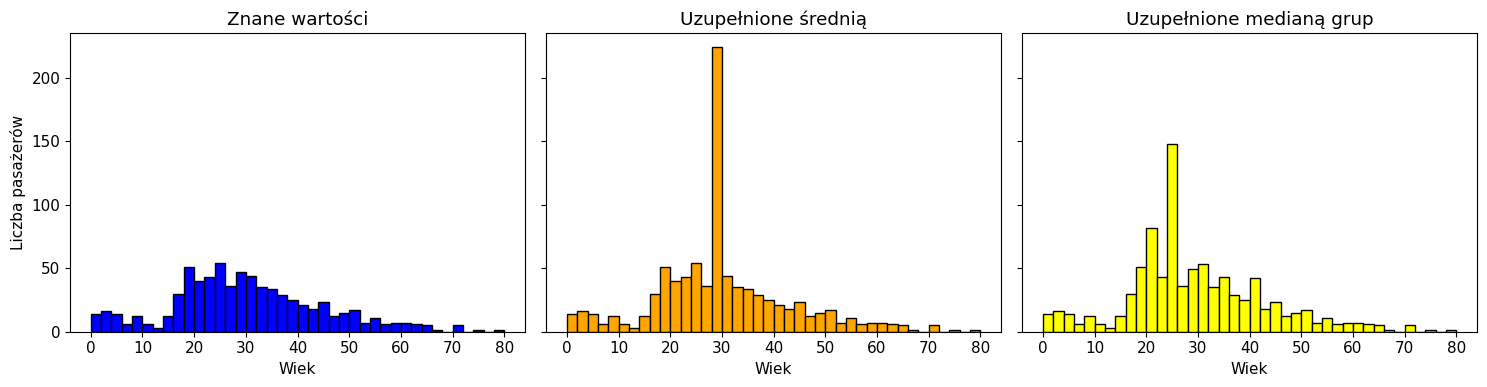

Odchylenia standardowe:
Oryginalny wiek (znany): 14.53
Uzupełniony średnią: 13.00
Uzupełniony grupami: 13.30


In [14]:
# 1)
titanic["Age_brak"] = titanic["Age"].isna()

# 2)
wiek_srednia = titanic["Age"].fillna(titanic["Age"].mean())
mediana_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
wiek_grupy = titanic["Age"].fillna(mediana_grup)

# 3)
przedzialy = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

titanic["Age"].dropna().plot.hist(bins=przedzialy, ax=axes[0], color="blue", edgecolor="black")
axes[0].set_title("Znane wartości")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")

wiek_srednia.plot.hist(bins=przedzialy, ax=axes[1], color="orange", edgecolor="black")
axes[1].set_title("Uzupełnione średnią")
axes[1].set_xlabel("Wiek")

wiek_grupy.plot.hist(bins=przedzialy, ax=axes[2], color="yellow", edgecolor="black")
axes[2].set_title("Uzupełnione medianą grup")
axes[2].set_xlabel("Wiek")

plt.tight_layout()
plt.show()

# 4)
print("Odchylenia standardowe:")
print(f"Oryginalny wiek (znany): {titanic['Age'].std():.2f}")
print(f"Uzupełniony średnią: {wiek_srednia.std():.2f}")
print(f"Uzupełniony grupami: {wiek_grupy.std():.2f}")

*Twoja odpowiedź:* Najbardziej zniekształca rozkład metoda uzupełniania średnią.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

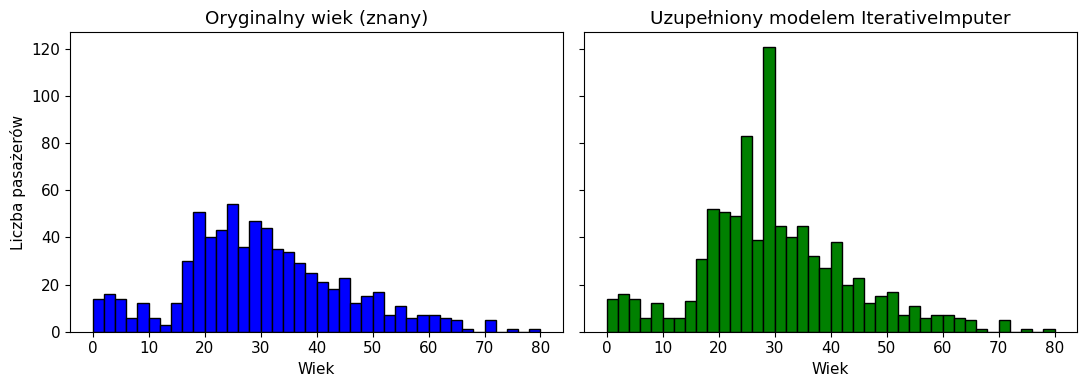

Odchylenia standardowe (std):
Oryginalny wiek (znany): 14.53
Uzupełniony średnią: 13.00
Uzupełniony grupami: 13.30
Uzupełniony modelem (MICE): 13.64


In [16]:
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

cechy = ["Pclass", "SibSp", "Parch", "Fare"]
dane_do_imputacji = titanic[["Age"] + cechy].copy()
dane_do_imputacji["Sex_bin"] = (titanic["Sex"] == "male").astype(int)

imputer = IterativeImputer(random_state=42)
wynik_imputacji = imputer.fit_transform(dane_do_imputacji)

wiek_model = pd.Series(wynik_imputacji[:, 0], index=titanic.index)

przedzialy = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

titanic["Age"].dropna().plot.hist(bins=przedzialy, ax=axes[0], color="blue", edgecolor="black")
axes[0].set_title("Oryginalny wiek (znany)")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")

wiek_model.plot.hist(bins=przedzialy, ax=axes[1], color="green", edgecolor="black")
axes[1].set_title("Uzupełniony modelem IterativeImputer")
axes[1].set_xlabel("Wiek")

plt.tight_layout()
plt.show()

print("Odchylenia standardowe (std):")
print(f"Oryginalny wiek (znany): {titanic['Age'].std():.2f}")
print(f"Uzupełniony średnią: {wiek_srednia.std():.2f}")
print(f"Uzupełniony grupami: {wiek_grupy.std():.2f}")
print(f"Uzupełniony modelem (MICE): {wiek_model.std():.2f}")

*Twoja odpowiedź:* Odchylenie standardowe dało najlepszy wynik ze wszystkich testowanych metod.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [17]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# 1)
print("Typy kolumn:")
print(mieszkania.dtypes)

# 2)
print("Liczba braków w kolumnach:")
print(mieszkania.isna().sum())
print(f"Łączna liczba braków wykrytych przez pandas: {mieszkania.isna().sum().sum()}")

print(mieszkania["powierzchnia"].unique())

Typy kolumn:
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object
Liczba braków w kolumnach:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
Łączna liczba braków wykrytych przez pandas: 8
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']


*Twoja odpowiedź:* Ponieważ liczby w niej są zapisane w pojedynczych cudzysłowach.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [18]:
# 1), 2)
for kol in mieszkania.columns:
    print(f"Kolumna: {kol}")
    print(mieszkania[kol].unique())
    print()

Kolumna: id
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45]

Kolumna: miasto
['Warszawa' 'Kraków' 'Wrocław' 'Poznań' 'Gdańsk']

Kolumna: dzielnica
['Mokotów' 'Krowodrza' 'Krzyki' 'Grunwald' 'Wrzeszcz' 'Śródmieście'
 'Podgórze' 'Stare Miasto' 'Jeżyce' 'Oliwa' 'Żoliborz' 'Kazimierz'
 'Psie Pole' 'Rataje' 'Siedlce' 'Praga' 'Nowa Huta' 'Fabryczna' 'Wilda'
 'Przymorze' 'Ochota' 'Bronowice' 'Centrum' 'Ursynów' 'Dębniki' 'Zaspa'
 'Wilanów' 'Łagiewniki' 'Biskupin' 'Sołacz' 'Chełm' 'Bielany' 'Ruczaj'
 'Gaj' 'Główna' 'Morena' 'Targówek' 'Mistrzejowice' 'Ołbin' 'Piątkowo'
 'Suchanino']

Kolumna: powierzchnia
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']

Kolumna: liczba_pokoi
[3 2 4 1 5]

Kolumna: rok_budowy
['2015' nan '2010' '2018' '1998' '2020' '2005' '2019' 'brak' '2001' '2016'
 '1995' '2

*Twoja odpowiedź*:

*   powierzchnia: 'brak', '0'
*   rok_budowy: 'brak'
*   pietro: 'brak', '-999'
*   parking, balkon: '?'
*   stan: '很好':
*   cena_m2: -1, -999




In [19]:
braki_slownik = {
    "powierzchnia": ["brak", "0", 0],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999", -999],
    "parking": ["?"],
    "balkon": ["?"],
    "stan": ["很好"],
    "cena_m2": [-1, -999, "-1", "-999"]
}

# 3)
mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

# 4)
print("Nowe typy kolumn:")
print(mieszkania.dtypes)

print("Liczba braków teraz:")
print(mieszkania.isna().sum())
print(f"Łącznie braków: {mieszkania.isna().sum().sum()}")

Nowe typy kolumn:
id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object
Liczba braków teraz:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             1
cena_m2          2
cena_total       0
dtype: int64
Łącznie braków: 30


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

W kolumnie stan jest jedna kolumna, która po przetłumaczeniu oznacza "bardzo dobry" (stan). W poprzedniej komórce ją usunąłem, jako "brak", natomiast można równie dobrze ją przetłumaczyć i zachować.

In [ ]:
print(mieszkania["stan"].value_counts(dropna=False))
mieszkania["stan"] = mieszkania["stan"].replace("很好", "Bardzo dobry")
print(mieszkania["stan"].value_counts(dropna=False))

**TUTAJ TO NIE ZADZIAŁA, PONIEWAŻ USUNĄŁEM JĄ WCZEŚNIEJ**

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

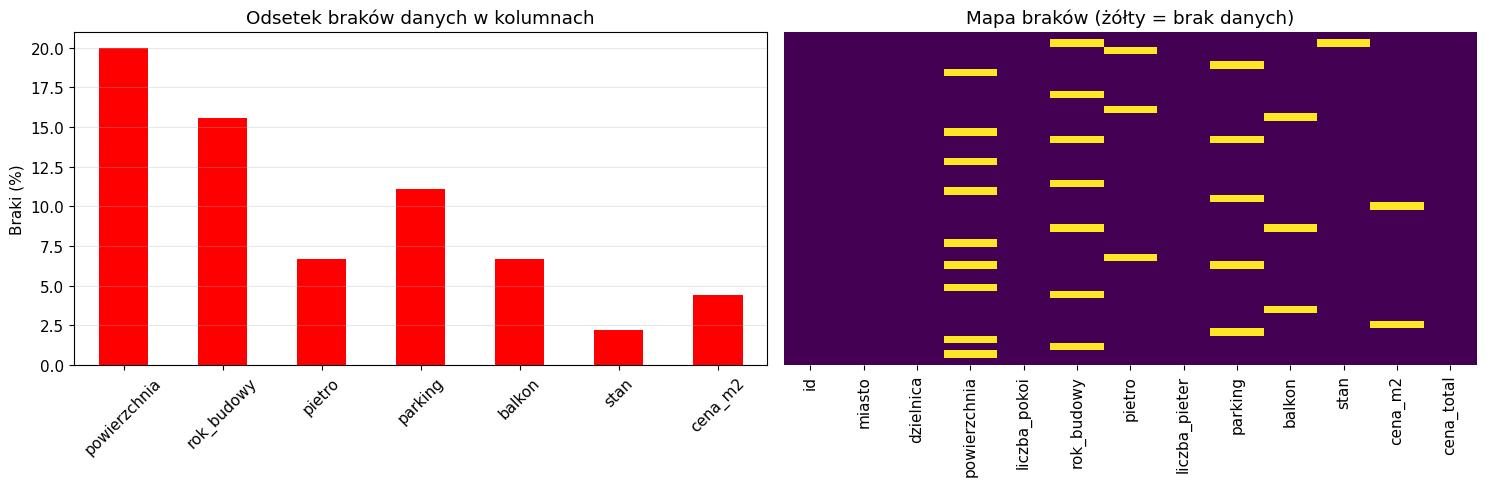

Korelacja występowania braków między kolumnami:


,powierzchnia,rok_budowy,pietro,parking,balkon,stan,cena_m2
powierzchnia,1.00,-0.21,-0.13,-0.00,-0.13,-0.08,-0.11
rok_budowy,-0.21,1.00,-0.11,0.04,0.13,0.35,-0.09
pietro,-0.13,-0.11,1.00,-0.09,-0.07,-0.04,-0.06
parking,-0.00,0.04,-0.09,1.00,-0.09,-0.05,-0.08
balkon,-0.13,0.13,-0.07,-0.09,1.00,-0.04,-0.06
stan,-0.08,0.35,-0.04,-0.05,-0.04,1.00,-0.03
cena_m2,-0.11,-0.09,-0.06,-0.08,-0.06,-0.03,1.00


In [22]:
# 1)
odsetek_brakow = mieszkania.isna().mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

odsetek_brakow[odsetek_brakow > 0].plot.bar(ax=axes[0], color="red", rot=45)
axes[0].set_title("Odsetek braków danych w kolumnach")
axes[0].set_ylabel("Braki (%)")
axes[0].grid(axis="y", alpha=0.3)

sns.heatmap(mieszkania.isna(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Mapa braków (żółty = brak danych)")

plt.tight_layout()
plt.show()

# 2)
kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()]
korelacja_brakow = mieszkania[kolumny_z_brakami].isna().corr()

print("Korelacja występowania braków między kolumnami:")
display(korelacja_brakow.round(2))

*Twoja odpowiedź:* Nie, braki w różnych kolumnach nie występują w tych samych wierszach.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [26]:
braki_pow_przed = mieszkania["powierzchnia"].isna().sum()
braki_cena_przed = mieszkania["cena_m2"].isna().sum()

kompletne = mieszkania.dropna(subset=["powierzchnia", "cena_m2", "cena_total"])
zgodnosc = (kompletne["cena_total"] == kompletne["powierzchnia"] * kompletne["cena_m2"]).all()
print(f"Czy występuje zależność?: {zgodnosc}")

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(mieszkania["cena_total"] / mieszkania["powierzchnia"])

braki_pow_po = mieszkania["powierzchnia"].isna().sum()
braki_cena_po = mieszkania["cena_m2"].isna().sum()

odtworzone_pow = braki_pow_przed - braki_pow_po
odtworzone_cena = braki_cena_przed - braki_cena_po

print(f"Odtworzono w powierzchni: {odtworzone_pow} braków (zostało braków: {braki_pow_po})")
print(f"Odtworzono w cenie: {odtworzone_cena} braków (zostało braków: {braki_cena_po})")
print(f"Łącznie odtworzono dokładnie: {odtworzone_pow + odtworzone_cena} braków")

Czy występuje zależność?: False
Odtworzono w powierzchni: 0 braków (zostało braków: 0)
Odtworzono w cenie: 0 braków (zostało braków: 0)
Łącznie odtworzono dokładnie: 0 braków


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [29]:
# 1)
kolumny_do_obslugi = ["rok_budowy", "pietro", "parking", "balkon"]
for kol in kolumny_do_obslugi:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna()

# 2)
mieszkania["stan"] = mieszkania["stan"].fillna("Bardzo dobry") # przetłumaczenie z języka chińskiego, aby wyeliminować jedyny brak

# a)
print("Mediany roku budowy wg miasta:")
print(mieszkania.groupby("miasto")["rok_budowy"].median())
print("Mediany roku budowy wg stanu:")
print(mieszkania.groupby("stan")["rok_budowy"].median())

mediana_rok_stan = mieszkania.groupby("stan")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_rok_stan)

# b)
srodkowe_pietro = mieszkania["liczba_pieter"] // 2
mieszkania["pietro"] = mieszkania["pietro"].fillna(srodkowe_pietro)

# c)
mieszkania["parking"] = mieszkania["parking"].fillna("nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("nieznane")

# 3)
print("Liczba braków w kolumnach po czyszczeniu:")
print(mieszkania.isna().sum())
print(f"Łączna liczba braków w zbiorze: {mieszkania.isna().sum().sum()}")

Mediany roku budowy wg miasta:
miasto
Gdańsk      2002.0
Kraków      2011.5
Poznań      2010.0
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
Mediany roku budowy wg stanu:
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
Liczba braków w kolumnach po czyszczeniu:
id                 0
miasto             0
dzielnica          0
powierzchnia       0
liczba_pokoi       0
rok_budowy         0
pietro             0
liczba_pieter      0
parking            0
balkon             0
stan               0
cena_m2            0
cena_total         0
rok_budowy_brak    0
pietro_brak        0
parking_brak       0
balkon_brak        0
dtype: int64
Łączna liczba braków w zbiorze: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

Statystyki surowe:


,powierzchnia,rok_budowy,cena_m2
count,36.00,38.00,43.00
mean,64.64,2010.29,10223.26
std,13.68,7.83,1611.69
min,42.00,1995.00,8200.00
25%,54.75,2004.25,9000.00
50%,63.00,2011.50,9800.00
75%,72.75,2016.75,11100.00
max,95.00,2022.00,15000.00



Statystyki oczyszczone:


,powierzchnia,rok_budowy,cena_m2
count,45.00,45.00,45.00
mean,64.93,2010.64,10244.34
std,12.76,7.41,1623.86
min,42.00,1995.00,8200.00
25%,56.00,2006.00,9000.00
50%,62.00,2011.00,9800.00
75%,72.00,2017.00,11200.00
max,95.00,2022.00,15000.00


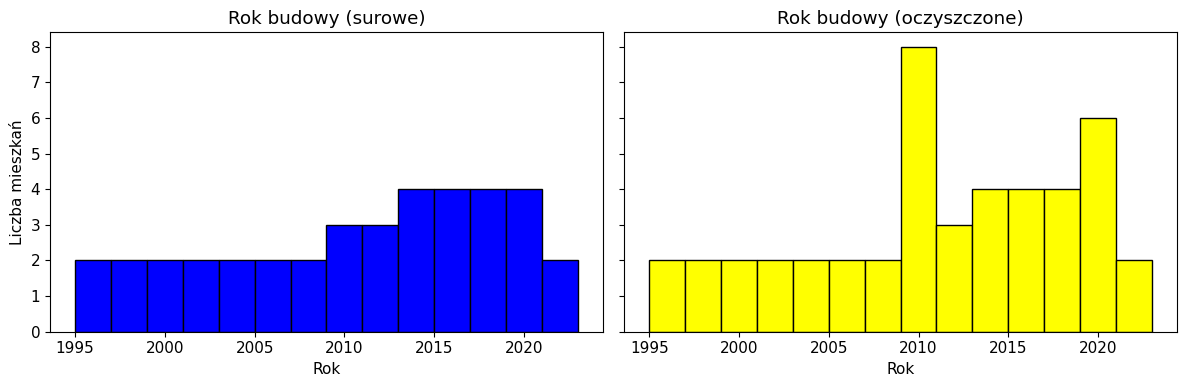

In [30]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

# 1)
kolumny = ["powierzchnia", "rok_budowy", "cena_m2"]

print("Statystyki surowe:")
display(surowe[kolumny].describe().round(2))
print("\nStatystyki oczyszczone:")
display(mieszkania[kolumny].describe().round(2))

# 2)
min_rok = int(mieszkania["rok_budowy"].min())
max_rok = int(mieszkania["rok_budowy"].max())
przedzialy = np.arange(min_rok, max_rok + 3, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

surowe["rok_budowy"].dropna().plot.hist(bins=przedzialy, ax=axes[0], color="blue", edgecolor="black")
axes[0].set_title("Rok budowy (surowe)")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba mieszkań")

mieszkania["rok_budowy"].plot.hist(bins=przedzialy, ax=axes[1], color="yellow", edgecolor="black")
axes[1].set_title("Rok budowy (oczyszczone)")
axes[1].set_xlabel("Rok")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Nie zmieniło w istotny sposób. Jedynie dla "rok_budowy" zwiększyła się liczba mieszkań w latach 2010 oraz 2020.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `NaN`, `'brak'`, `'0'` | 9 | odtworzenie wzorem (`cena_total / cena_m2`) | znamy dokładną relację |
| `cena_m2` | `-1`, `-999` | 2 | odtworzenie wzorem (`cena_total / powierzchnia`) | znamy dokładną relację |
| `rok_budowy` | `NaN`, `'brak'` | 7 | flaga braku, mediana w grupach wg. `stan` | rok budowy koreluje ze stanem |
| `pietro` | `'brak'`, `'-999'` | 3 | flaga braku, środkowe piętro (`liczba_pieter // 2`) | dopasowanie do wysokości budynku (wartość 0 zachowano jako parter) |
| `parking` | `'?'` | 5 | flaga braku + kategoria `"nieznane"` | inna metoda sztucznie zawyżyłaby odsetek mieszkań z parkingiem |
| `balkon` | `'?'` | 3 | flaga braku + kategoria `"nieznane"` | inna metoda sztucznie zawyżyłaby odsetek mieszkań z balkonem |
| `stan` | `'很好'` | 1 | tłumaczenie na `"Bardzo dobry"` | odzyskanie przetłumaczonej wartości |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [31]:
rok_surowy = surowe["rok_budowy"]
cena = mieszkania["cena_m2"]
kor_oryginal = rok_surowy.corr(cena)

# 1)
rok_mediana = rok_surowy.fillna(rok_surowy.median())
kor_mediana = rok_mediana.corr(cena)

# 2)
mediana_miasto = surowe.groupby("miasto")["rok_budowy"].transform("median")
rok_miasto = rok_surowy.fillna(mediana_miasto)
kor_miasto = rok_miasto.corr(cena)

# 3)
mediana_stan = surowe.groupby(mieszkania["stan"])["rok_budowy"].transform("median")
rok_stan = rok_surowy.fillna(mediana_stan)
kor_stan = rok_stan.corr(cena)

print(f"Korelacja oryginalna (bez braków): {kor_oryginal:.4f}")
print(f"1. Mediana całościowa: {kor_mediana:.4f} (różnica: {abs(kor_mediana - kor_oryginal):.4f})")
print(f"2. Mediana wg miasta: {kor_miasto:.4f} (różnica: {abs(kor_miasto - kor_oryginal):.4f})")
print(f"3. Mediana wg stanu: {kor_stan:.4f} (różnica: {abs(kor_stan - kor_oryginal):.4f})")

Korelacja oryginalna (bez braków): 0.7087
1. Mediana całościowa: 0.6779 (różnica: 0.0308)
2. Mediana wg miasta: 0.7101 (różnica: 0.0014)
3. Mediana wg stanu: 0.6973 (różnica: 0.0114)


*Twoja odpowiedź:* Najmniej zmienia korelację wariant 2 - mediana w grupach według miasta.

Eksperyment z Bielikiem:

**Odpowiedź z Bielika:**

Oto niektóre nieścisłości i błędy w tabeli:

Brakujące wartości:

W wielu wierszach brakuje wartości dla kolumn takich jak pietro, liczba_pieter, parking, balkon, stan, cena_m2, cena_total.
Przykłady:
Wiersz 5: Brak wartości dla parking.
Wiersz 12: Brak wartości dla balkon.
Wiersz 40: cena_m2 wynosi -999, co jest nielogiczne.
Niespójności w danych:

Wiersz 11: pietro wynosi -999, co nie ma sensu w kontekście nieruchomości.
Wiersz 24: cena_m2 wynosi -1, co jest niemożliwe.
Niejasne oznaczenia:

W niektórych wierszach użyto NA lub brak zamiast konkretnych wartości, co utrudnia analizę.
Przykład: Wiersz 3: rok_budowy to brak.
Błędy w formatowaniu:

W wierszu 2 użyto chińskiego znaku 很好 zamiast polskiego lub angielskiego odpowiednika dla kolumny stan.
Niespójności w jednostkach:

Wszystkie wartości powierzchnia są podane w metrach kwadratowych, co jest spójne.
Wszystkie wartości cena_m2 i cena_total są podane w złotych, co również jest spójne.
Powtórzenia i braki:

W wierszu 45, dzielnica to Suchanino, ale w innych wierszach dla Gdańska użyto różnych dzielnic, co jest spójne.
W wierszu 29, powierzchnia wynosi 0, co jest nielogiczne dla nieruchomości.
Niejasne wartości liczbowe:

W wierszu 14, powierzchnia wynosi 0, co jest niemożliwe.
W wierszu 40, cena_m2 wynosi -999, co jest niemożliwe.
Błędy w nazwach miast i dzielnic:

Wszystkie nazwy miast i dzielnic wydają się poprawne, ale warto sprawdzić, czy nie ma literówek.
Niespójności w latach budowy:

W wierszu 24, rok_budowy to 2021, ale cena_m2 jest ustawiona na -1, co jest niemożliwe.
Brakujące informacje o stanie nieruchomości:

W wielu wierszach brakuje informacji o stanie nieruchomości, co jest kluczowe dla oceny wartości.
Aby poprawić tę tabelę, należałoby:

Uzupełnić brakujące wartości.
Poprawić niespójności i błędy w danych.
Ujednolicić formatowanie i oznaczenia.
Upewnić się, że wszystkie wartości są logiczne i mają sens w kontekście nieruchomości.

**Odpowiedź (moja):** Model poprawnie zidentyfikował główne anomalie (chińskie znaki, ujemne ceny -1/-999, metraż 0 oraz tekst "brak"). Nie poradził sobie jednak z innymi danymi. Zhalucynował braki danych w kolumnach cena_total i liczba_pieter, które były kompletne. Przeoczył pułapkę parteru (pietro = 0), nie definiując, co z nim zrobić. Nie zauważył relacji matematycznej, przez co nie zaproponował dokładnego odtworzenia powierzchni i ceny ze wzorów.

